## Latar belakang

Indonesia has a relatively high annual incidence of dengue fever (DHF). This disease, caused by the dengue virus, can lead to severe complications and even death if it is not detected and treated at an early stage. Therefore, early identification of potential dengue infection is crucial for effective prevention and patient management.

This study utilizes the **Dengue_Fever_Hematological_Dataset**, which contains hematological variables such as hemoglobin levels (g/dL), mean platelet volume (MPV, fl), and other medical parameters relevant to DHF diagnosis. Based on this dataset, we developed a machine learning model capable of automatically classifying a patient’s condition as indicative of DHF. This approach is expected to assist medical personnel by accelerating the early detection process and improving accuracy in minimizing the risk of severe and fatal outcomes.

## **Exploratory Data Analysis**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder
from sklearn.metrics import  accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, classification_report, make_scorer, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv('Dengue_Fever_Hematological_Dataset.csv')
df.head()

,Gender,Age,Hemoglobin(g/dl),Neutrophils(%),Lymphocytes(%),Monocytes(%),Eosinophils(%),RBC,HCT(%),MCV(fl),MCH(pg),MCHC(g/dl),RDW-CV(%),Total Platelet Count(/cumm),MPV(fl),PDW(%),PCT(%),Total WBC count(/cumm),Result
0,Male,21.0,14.8,48.0,47.0,3.0,2.0,5.0,48.00,96.0,29.60,30.8,11.6,112000.0,10.70,15.40,0.120,5100.0,positive
1,Male,30.0,15.0,47.0,49.0,6.0,3.0,5.0,49.80,96.1,28.40,29.5,11.8,96000.0,10.60,15.80,0.121,4500.0,positive
2,Male,51.0,16.3,41.0,48.0,4.0,5.0,5.0,50.10,93.5,31.30,32.7,13.5,184000.0,10.40,16.40,0.130,6000.0,negative
3,Female,26.0,12.3,46.0,49.0,7.0,5.0,5.0,44.00,90.0,30.50,30.5,14.7,167000.0,8.10,17.10,0.110,5000.0,negative
4,Male,35.0,16.1,45.0,46.0,4.0,4.0,5.0,50.53,91.0,29.12,29.2,15.2,155000.0,10.52,12.34,0.150,4600.0,negative


### **Describe Dataset Information**

In [ ]:
# Check Dataset Informations (Shape, columns, info)
print(df.shape, "\n")


(1548, 19) 



In [ ]:
print(df.columns, "\n")


Index(['Gender', 'Age', 'Hemoglobin(g/dl)', 'Neutrophils(%)', 'Lymphocytes(%)',
       'Monocytes(%)', 'Eosinophils(%)', 'RBC', 'HCT(%)', 'MCV(fl)', 'MCH(pg)',
       'MCHC(g/dl)', 'RDW-CV(%)', 'Total Platelet Count(/cumm)', 'MPV(fl)',
       'PDW(%)', 'PCT(%)', 'Total WBC count(/cumm)', 'Result'],
      dtype='object') 



In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1548 entries, 0 to 1547
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Gender                       1545 non-null   object 
 1   Age                          1540 non-null   float64
 2   Hemoglobin(g/dl)             1540 non-null   float64
 3   Neutrophils(%)               1541 non-null   float64
 4   Lymphocytes(%)               1543 non-null   float64
 5   Monocytes(%)                 1543 non-null   float64
 6   Eosinophils(%)               1539 non-null   float64
 7   RBC                          1545 non-null   float64
 8   HCT(%)                       1542 non-null   float64
 9   MCV(fl)                      1542 non-null   float64
 10  MCH(pg)                      1539 non-null   float64
 11  MCHC(g/dl)                   1544 non-null   float64
 12  RDW-CV(%)                    1542 non-null   float64
 13  Total Platelet Cou

In [ ]:
# check dataset statistics
df.describe()

,Age,Hemoglobin(g/dl),Neutrophils(%),Lymphocytes(%),Monocytes(%),Eosinophils(%),RBC,HCT(%),MCV(fl),MCH(pg),MCHC(g/dl),RDW-CV(%),Total Platelet Count(/cumm),MPV(fl),PDW(%),PCT(%),Total WBC count(/cumm)
count,1540.000000,1540.000000,1541.000000,1543.000000,1543.000000,1539.000000,1545.000000,1542.000000,1542.000000,1539.000000,1544.000000,1542.000000,1.543000e+03,1538.000000,1545.000000,1545.000000,1545.000000
mean,41.527650,14.931962,45.706179,44.738181,3.364066,3.171129,4.898226,46.444111,92.278098,30.732454,32.944957,14.020086,1.778521e+05,9.854300,15.740109,0.294862,5630.199387
std,53.084435,18.350809,56.121545,54.961225,4.290063,4.010724,6.033401,56.946906,113.073824,37.699929,40.319839,17.217689,2.269807e+05,12.103144,19.294012,5.960944,6977.709802
min,-208.386258,-74.941437,-229.431063,-224.557912,-16.888018,-15.920365,-24.590128,-233.115873,-463.213491,-154.266775,-165.360020,-70.381529,-8.925351e+05,-49.458293,-79.005807,-1.479592,-28263.824845
25%,28.000000,13.200000,42.000000,41.000000,2.000000,2.000000,4.000000,42.560000,85.100000,28.400000,30.900000,12.400000,1.143130e+05,8.900000,14.230000,0.106000,4627.000000
50%,39.000000,14.600000,45.000000,44.000000,3.000000,3.000000,5.000000,45.535000,89.650000,30.000000,32.000000,13.800000,1.672080e+05,9.660000,15.260000,0.141000,5391.000000
75%,53.000000,15.800000,48.000000,47.000000,4.000000,4.000000,5.000000,47.855000,94.200000,31.400000,33.200000,14.700000,2.287035e+05,10.283000,16.400000,0.173000,6124.000000
max,2019.967532,726.193792,2223.653472,2176.571614,163.642255,154.288499,238.349515,2259.398401,4489.740597,1495.098278,1602.712176,682.112549,8.649268e+06,479.335988,765.722395,234.000000,273981.877023


### **Check data anomalies (missing values, duplicated rows, inconsitency)**

In [ ]:
# Check missing values
df.isnull().sum()

,0
Gender,3
Age,8
Hemoglobin(g/dl),8
Neutrophils(%),7
Lymphocytes(%),5
Monocytes(%),5
Eosinophils(%),9
RBC,3
HCT(%),6
MCV(fl),6


In [ ]:
# Check duplicated Values





duplicated rows : 34


In [ ]:
df['Gender'].value_counts()

,count
Gender,
Female,808
Male,711
Ma,17
fe male,9


In [ ]:
df['Result'].value_counts()

,count
Result,
positive,1056
negative,492


### **Check data distribution and outlier**

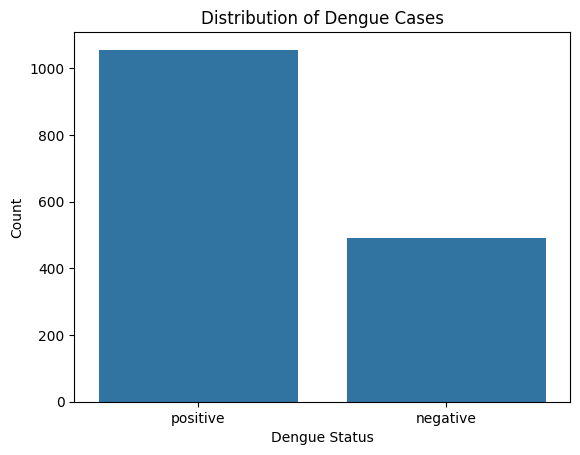

In [ ]:
# Check target distribution
sns.countplot(x='Result', data=df)
plt.title('Distribution of Dengue Cases')
plt.xlabel('Dengue Status')
plt.ylabel('Count')
plt.show()

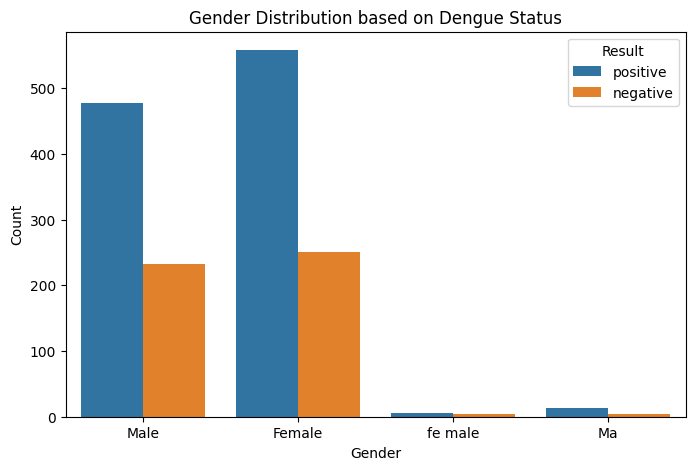

In [ ]:
# Check Gender distribution based on target variable
plt.figure(figsize=(8,5))
sns.countplot(x='Gender', hue='Result', data=df)
plt.title("Gender Distribution based on Dengue Status")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

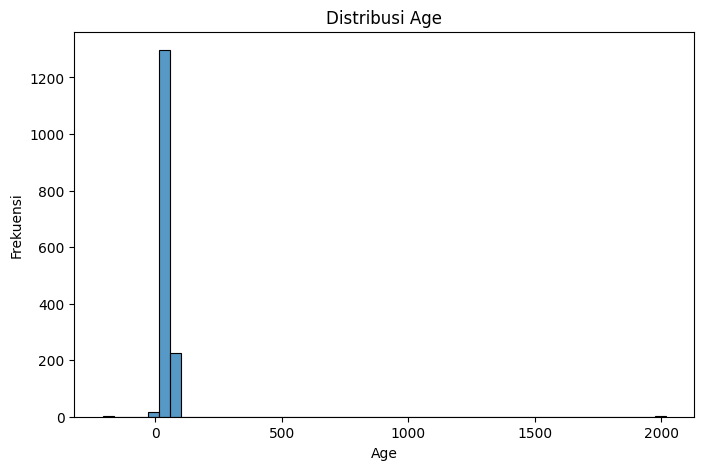

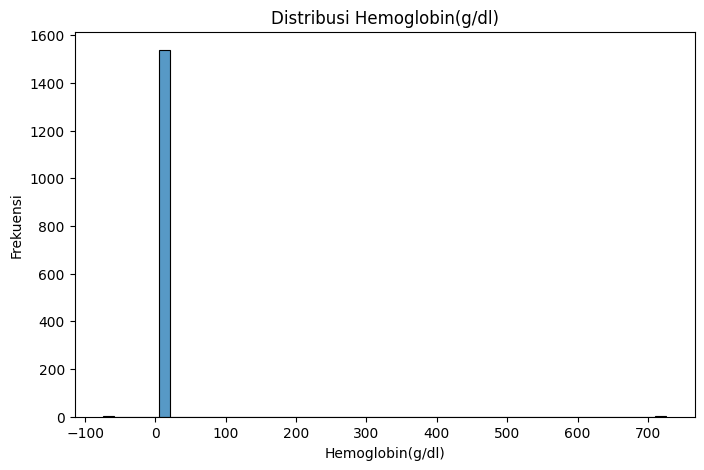

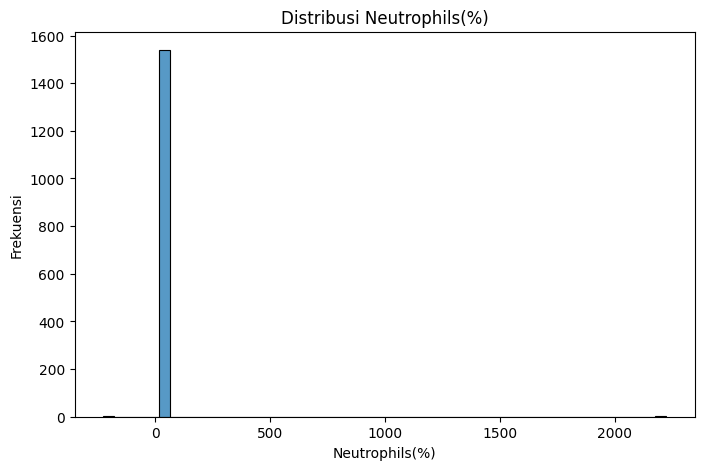

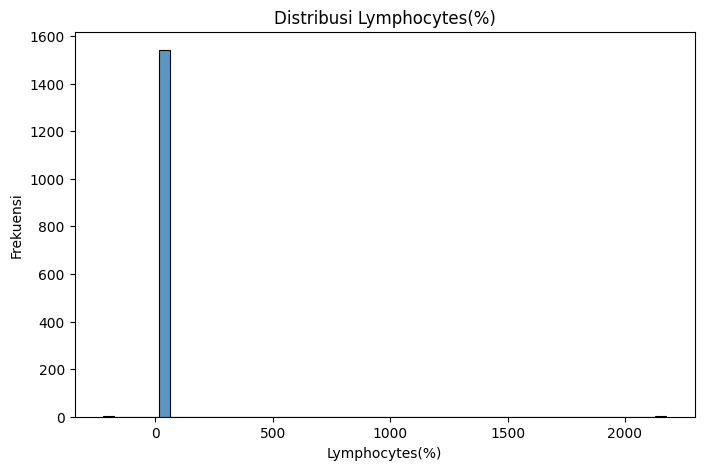

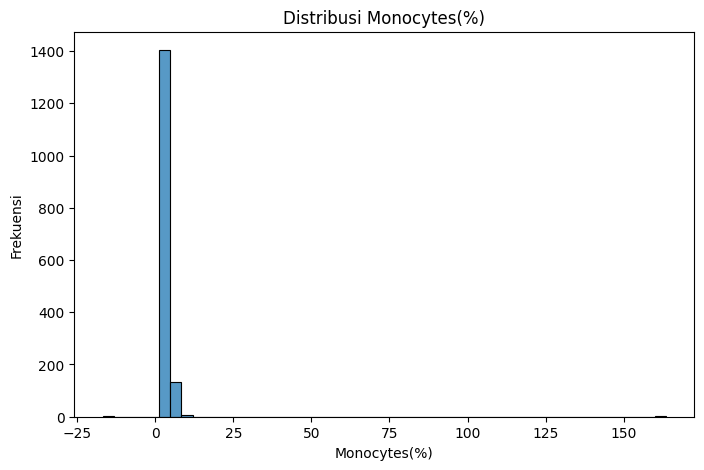

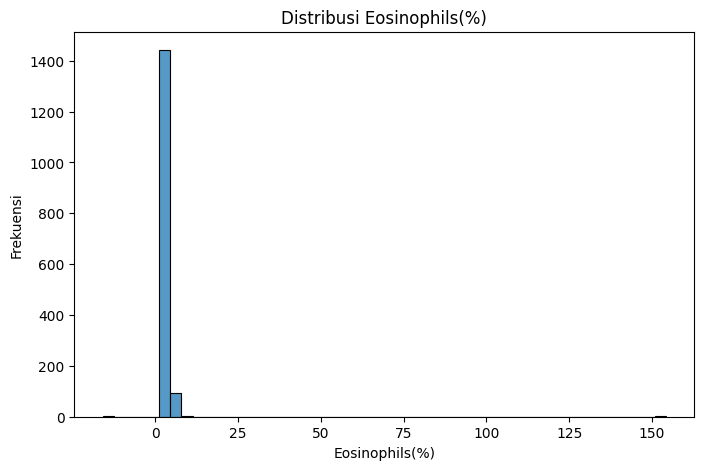

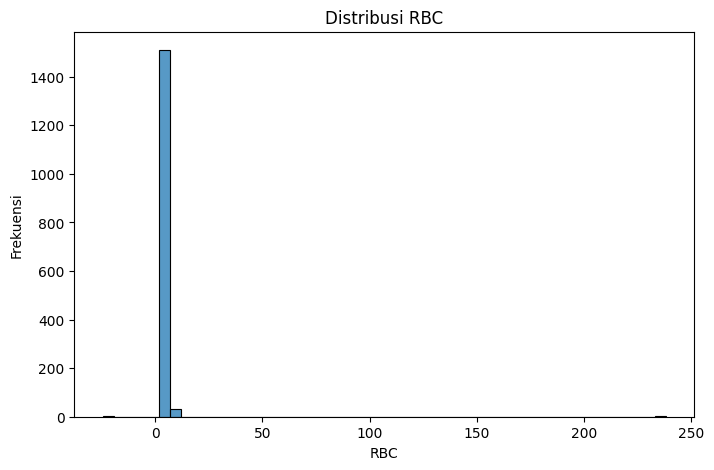

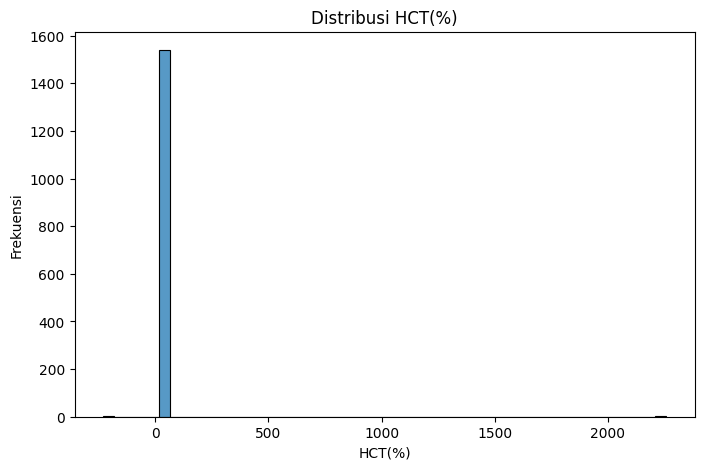

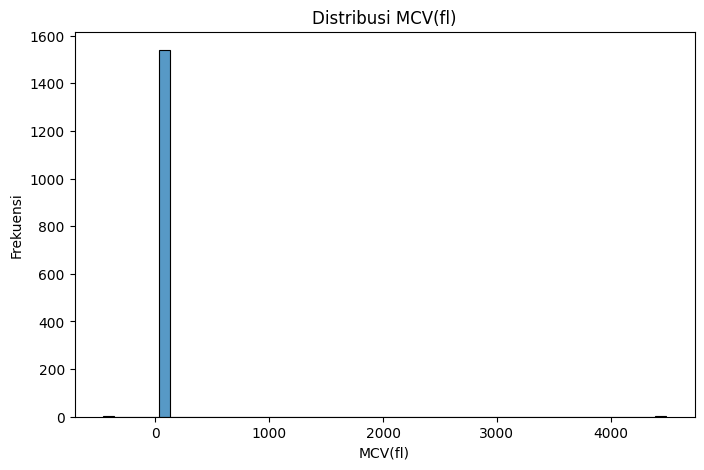

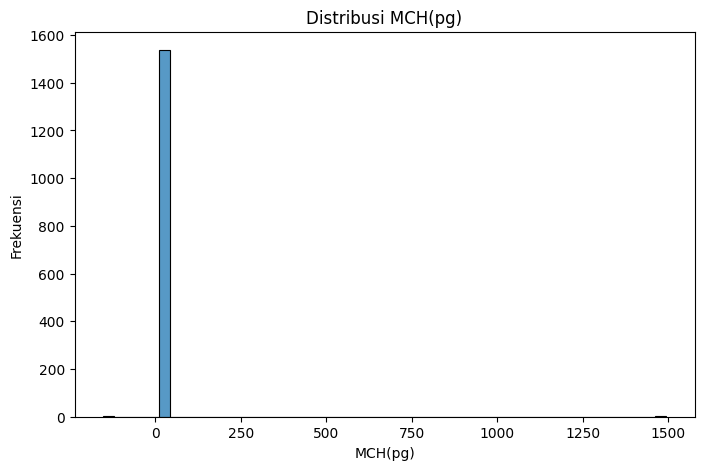

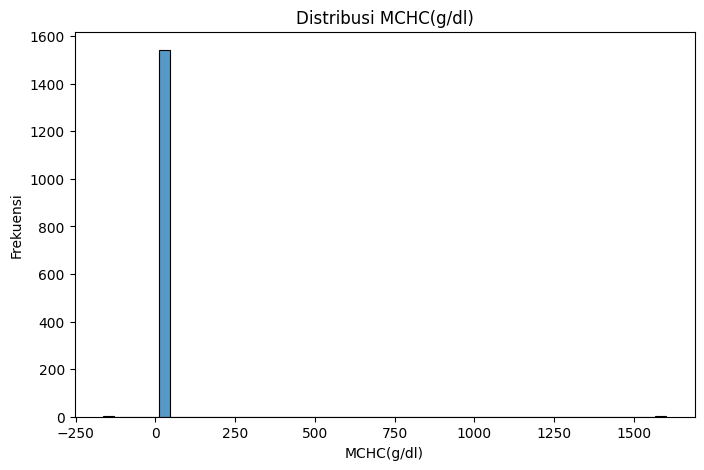

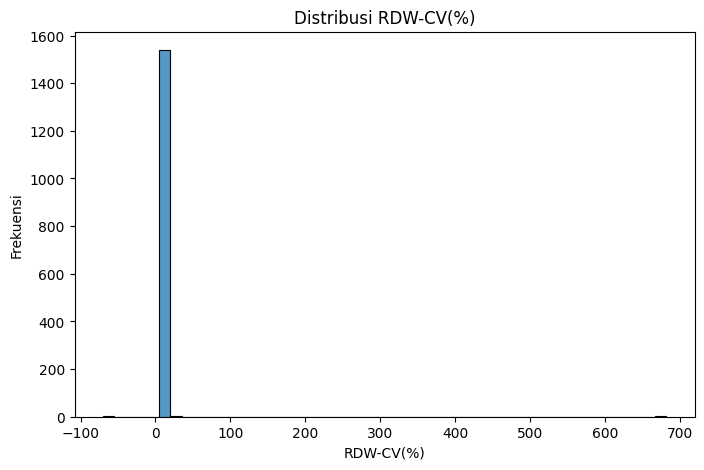

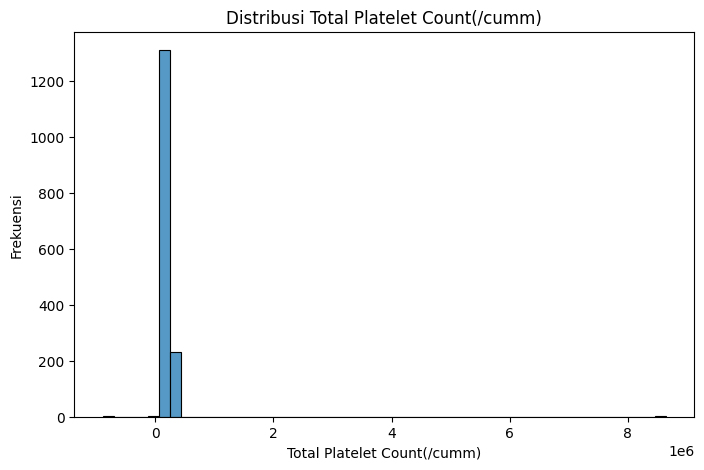

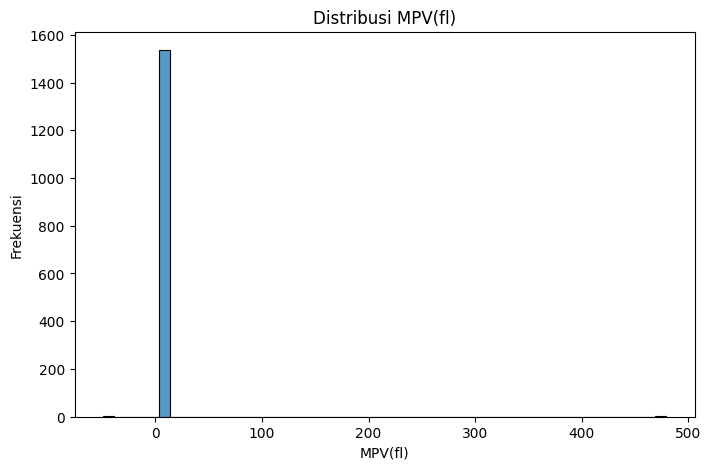

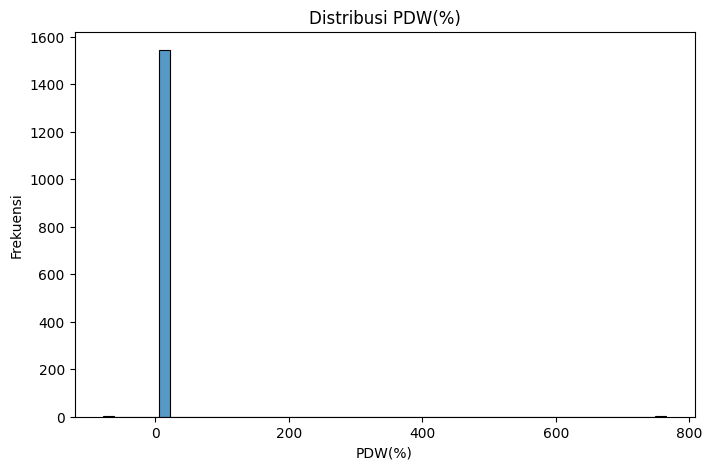

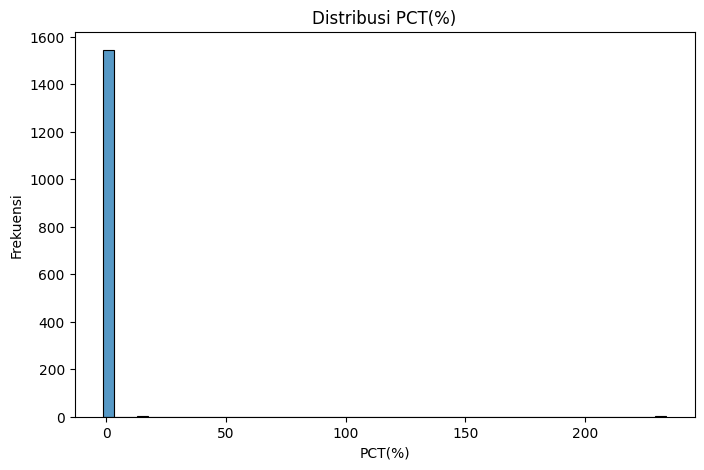

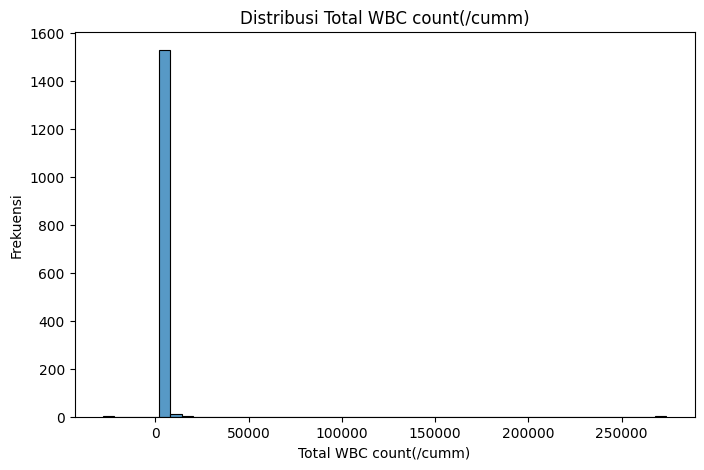

In [ ]:
# Check the distribution
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
for i in num_cols:
    plt.figure(figsize=(8,5))
    sns.histplot(df[i], bins=50)
    plt.title(f"Distribusi {i}")
    plt.xlabel(i)
    plt.ylabel("Frekuensi")
    plt.show()

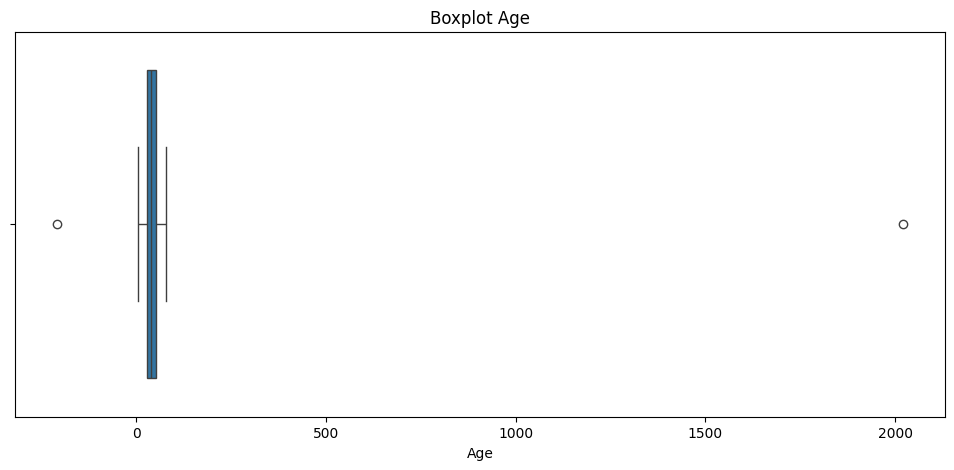

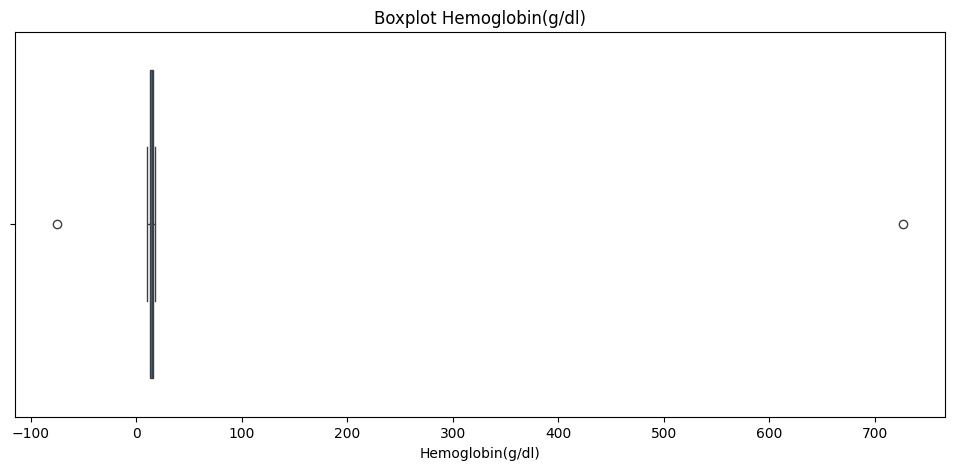

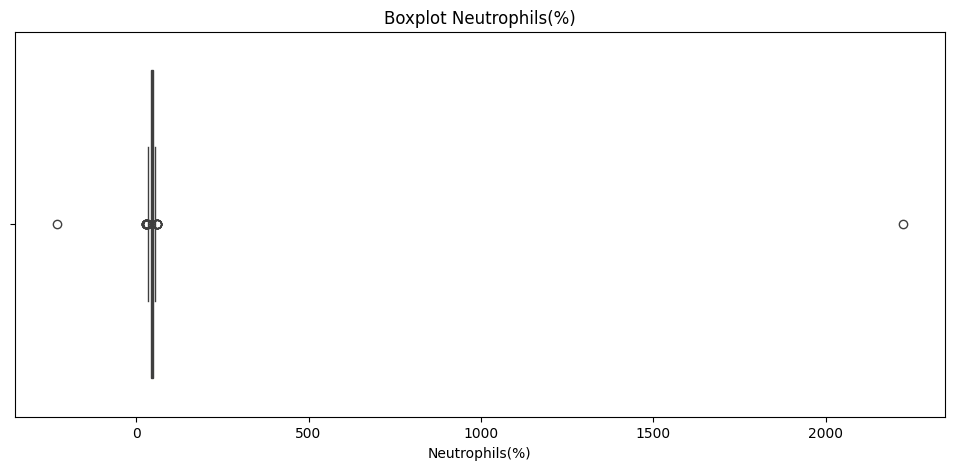

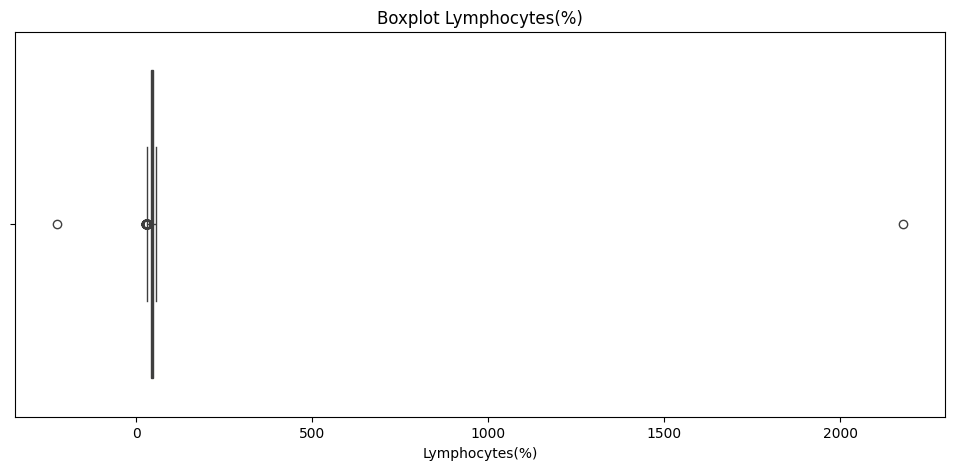

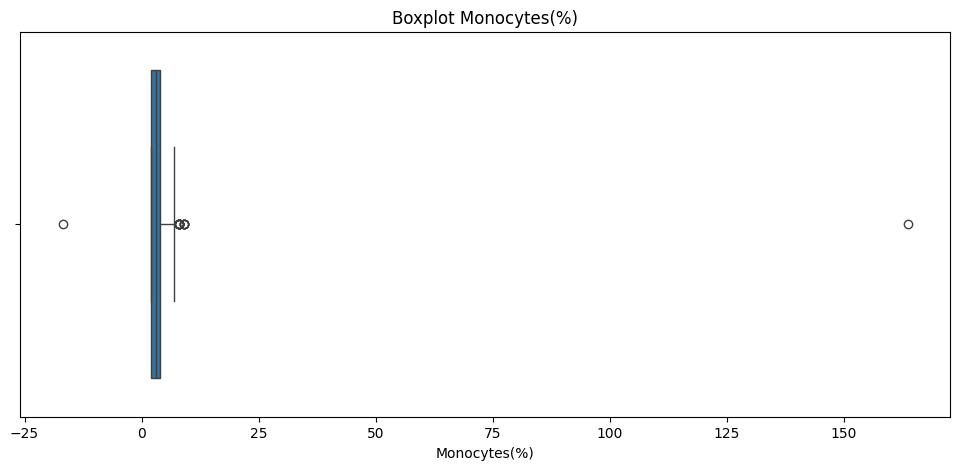

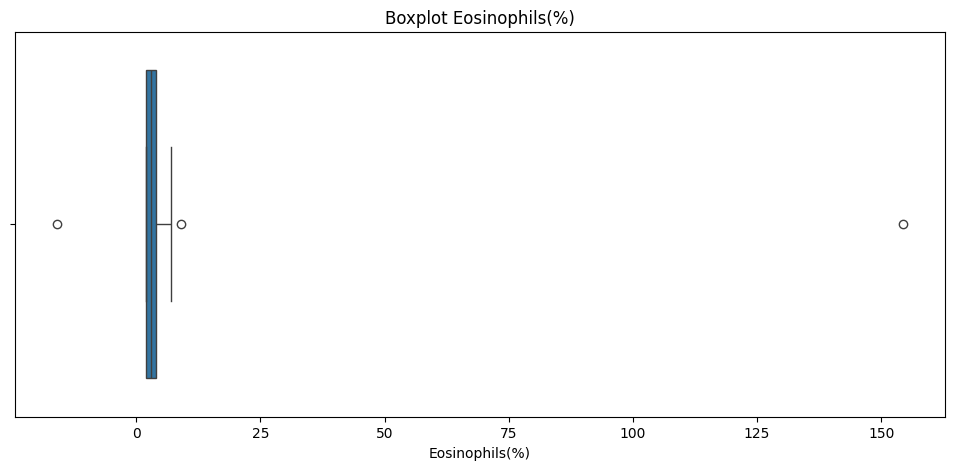

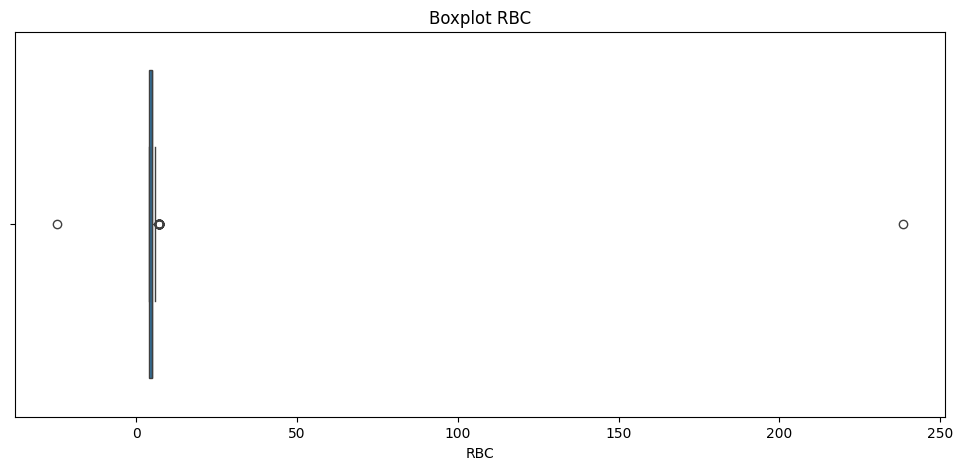

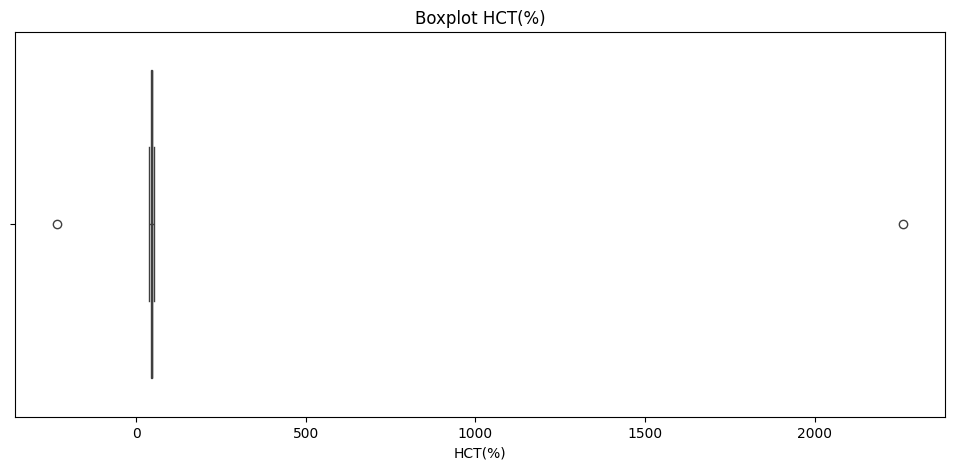

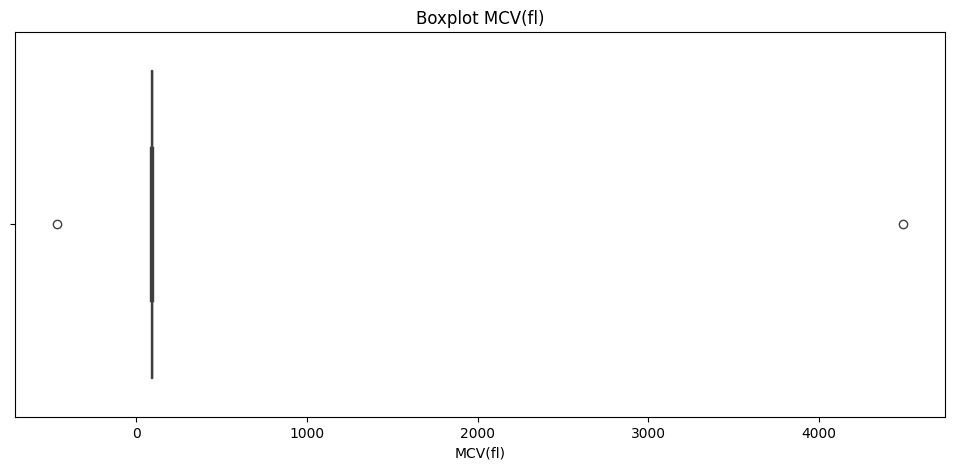

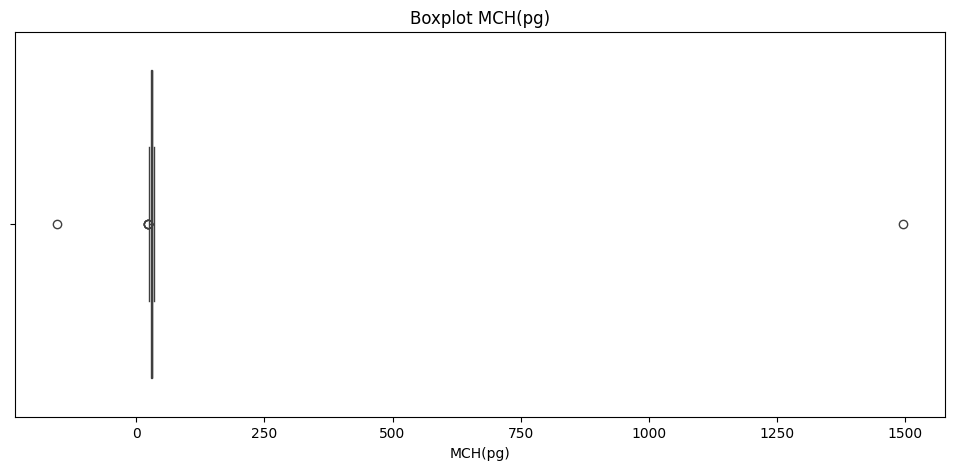

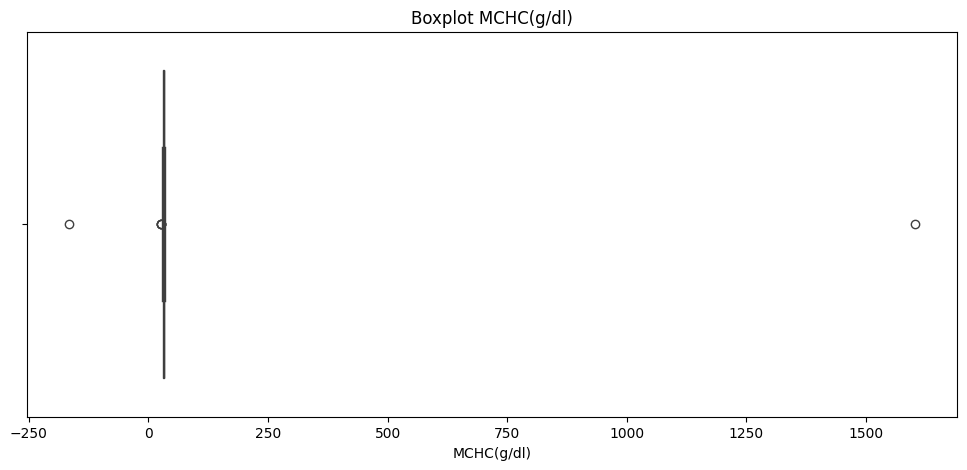

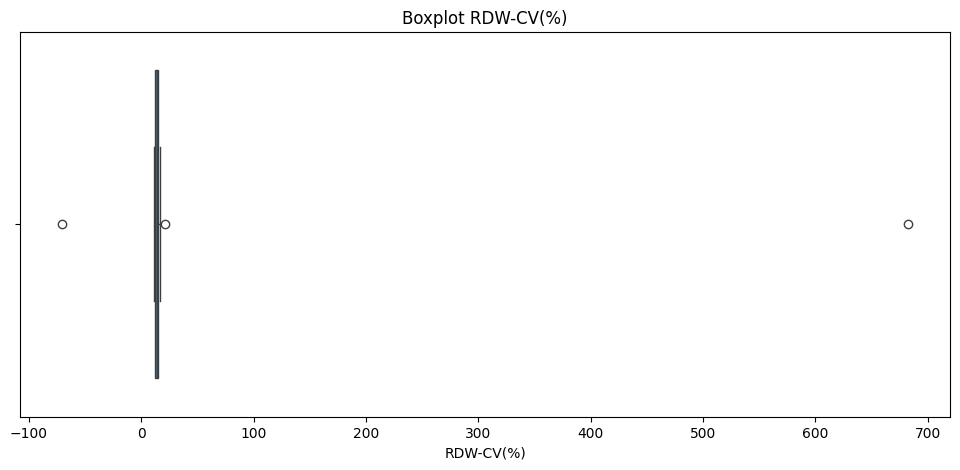

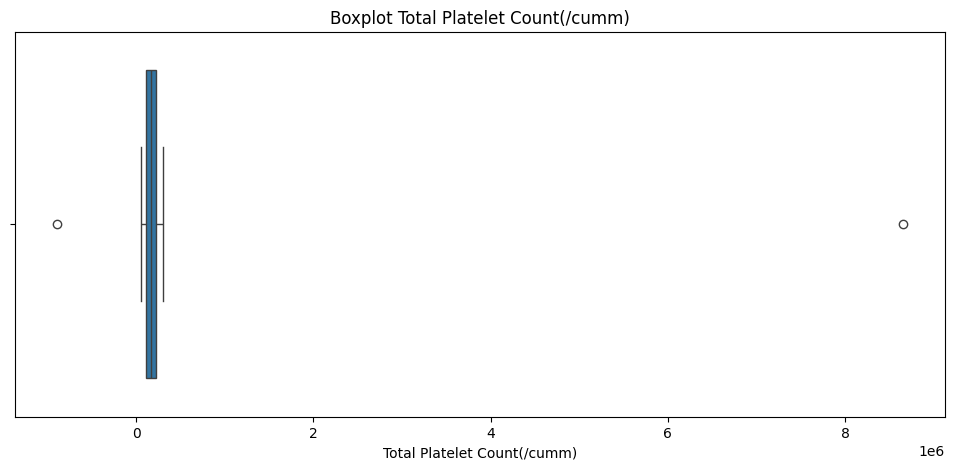

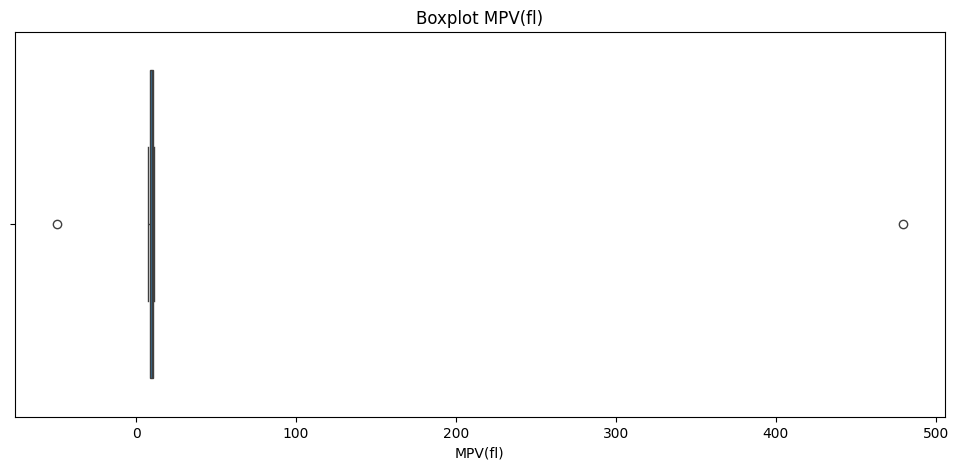

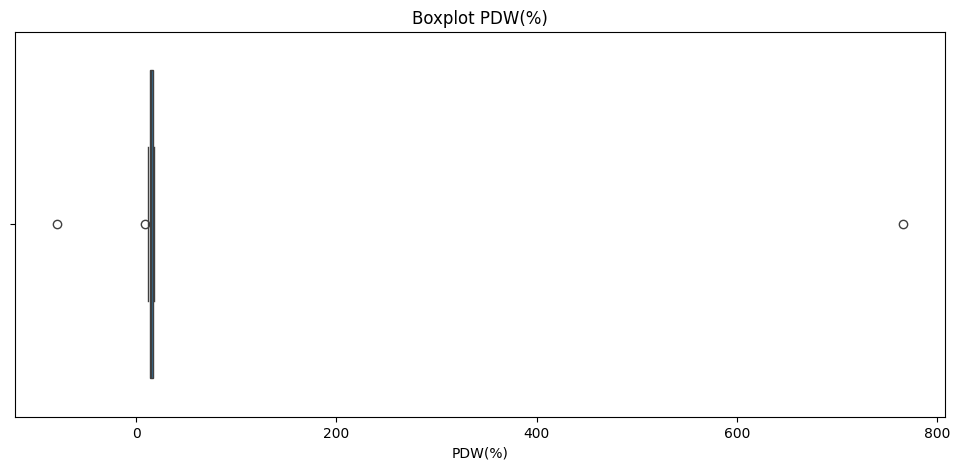

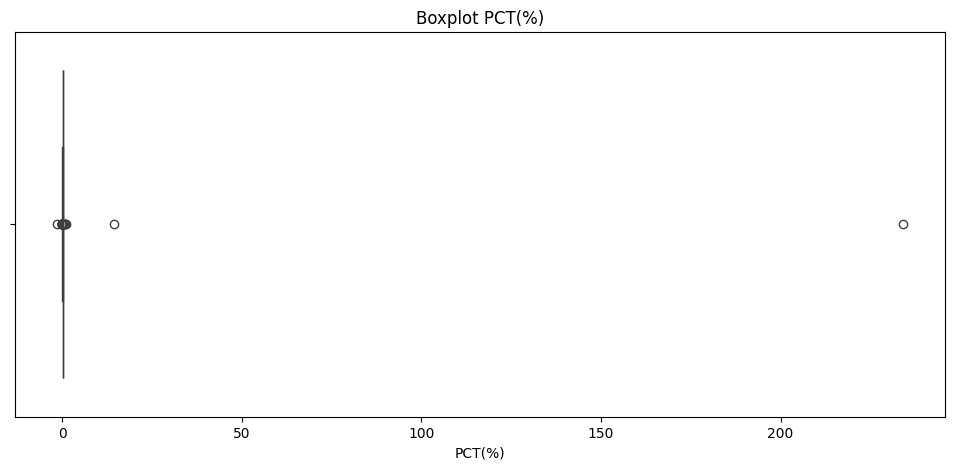

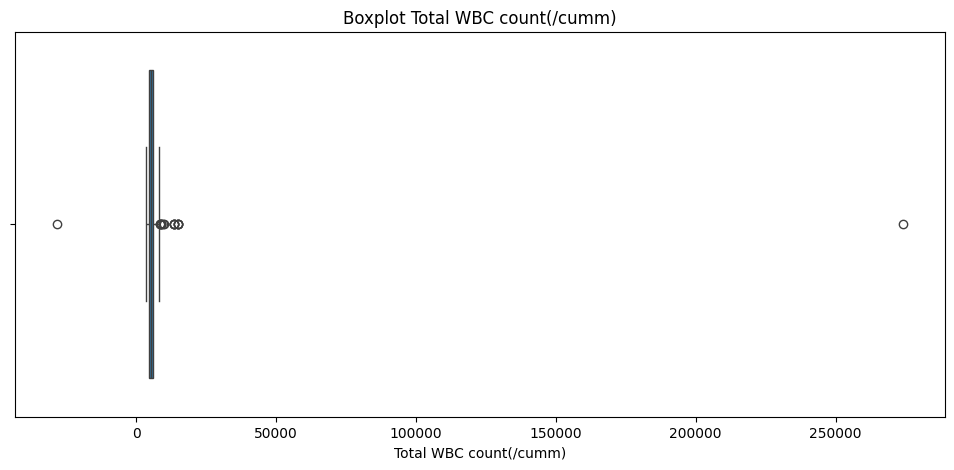

In [ ]:
# Visualisasi boxplot untuk tiap kolom numerik
for i in num_cols:
    plt.figure(figsize=(12,5))
    sns.boxplot(x=df[i])
    plt.title(f"Boxplot {i}")
    plt.xlabel(i)
    plt.show()

In [ ]:
print("\n===== DETEKSI OUTLIER (IQR) =====")
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    print(f"{col}: {outliers} outlier(s)")


===== DETEKSI OUTLIER (IQR) =====
Age: 2 outlier(s)
Hemoglobin(g/dl): 2 outlier(s)
Neutrophils(%): 38 outlier(s)
Lymphocytes(%): 74 outlier(s)
Monocytes(%): 19 outlier(s)
Eosinophils(%): 3 outlier(s)
RBC: 35 outlier(s)
HCT(%): 2 outlier(s)
MCV(fl): 2 outlier(s)
MCH(pg): 6 outlier(s)
MCHC(g/dl): 6 outlier(s)
RDW-CV(%): 3 outlier(s)
Total Platelet Count(/cumm): 2 outlier(s)
MPV(fl): 2 outlier(s)
PDW(%): 3 outlier(s)
PCT(%): 45 outlier(s)
Total WBC count(/cumm): 17 outlier(s)


### **Data Problems Conclusion**
1. Has missing value
2. Had some Duplicated data
3. Some Feature has negative values such as Age column, which is imposible.
4. Some feature has extreme outliers.
5. There is an inconsistent values in Geder feature.


## **Data preprocessing**

### **Handle Data Anomalies**

In [ ]:
# Handle missing values by dropping rows with missing values
df_clean = df.dropna()

In [ ]:
# drop uninform column
df_clean = df_clean.drop(columns=['Gender','Age'])

In [ ]:
# handle negative values, by deleting it
numerical_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns
for col in numerical_cols:
    df_clean = df_clean[df_clean[col] >= 0]

In [ ]:
# Handle Outliers using IQR method
for col in numerical_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]

In [ ]:
df_clean = df_clean.drop_duplicates(keep='first')

In [ ]:
df_clean.info()# Handle duplicate values

<class 'pandas.core.frame.DataFrame'>
Index: 1153 entries, 0 to 1522
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Hemoglobin(g/dl)             1153 non-null   float64
 1   Neutrophils(%)               1153 non-null   float64
 2   Lymphocytes(%)               1153 non-null   float64
 3   Monocytes(%)                 1153 non-null   float64
 4   Eosinophils(%)               1153 non-null   float64
 5   RBC                          1153 non-null   float64
 6   HCT(%)                       1153 non-null   float64
 7   MCV(fl)                      1153 non-null   float64
 8   MCH(pg)                      1153 non-null   float64
 9   MCHC(g/dl)                   1153 non-null   float64
 10  RDW-CV(%)                    1153 non-null   float64
 11  Total Platelet Count(/cumm)  1153 non-null   float64
 12  MPV(fl)                      1153 non-null   float64
 13  PDW(%)                 

In [ ]:
print(f"Jumlah Data yang terduplikat: {df_clean.duplicated().sum()} data.")

Jumlah Data yang terduplikat: 0 data.


In [ ]:
# FInal dataset we used
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Hemoglobin(g/dl),1153.0,14.540275,1.642515,11.4000,13.100,14.600,15.900,17.5000
Neutrophils(%),1153.0,44.756288,3.385339,33.0000,42.000,45.000,48.000,55.0000
Lymphocytes(%),1153.0,44.184735,3.702201,32.0000,41.000,44.000,47.000,56.0000
Monocytes(%),1153.0,3.121422,0.987333,2.0000,2.000,3.000,4.000,7.0000
Eosinophils(%),1153.0,3.064180,0.912515,2.0000,2.000,3.000,4.000,7.0000
RBC,1153.0,4.644406,0.605391,4.0000,4.000,5.000,5.000,6.0000
HCT(%),1153.0,45.090154,3.710593,38.0000,41.980,45.360,47.910,51.9800
MCV(fl),1153.0,89.718387,5.568478,80.0000,85.000,89.500,94.200,99.9000
MCH(pg),1153.0,29.926166,2.096188,26.0000,28.300,29.940,31.600,34.0000
MCHC(g/dl),1153.0,32.255440,1.500877,28.0900,31.000,32.200,33.500,35.0000


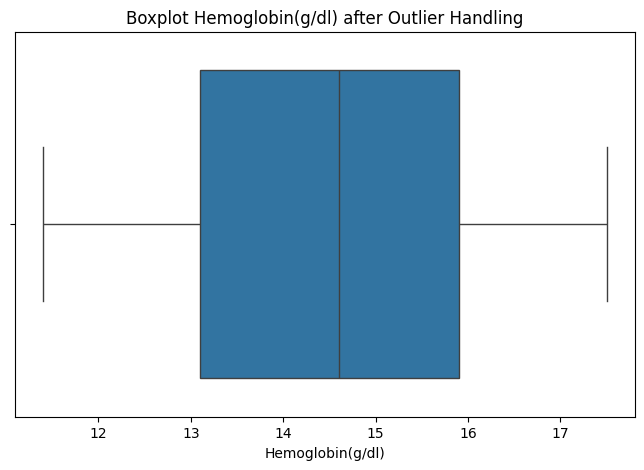

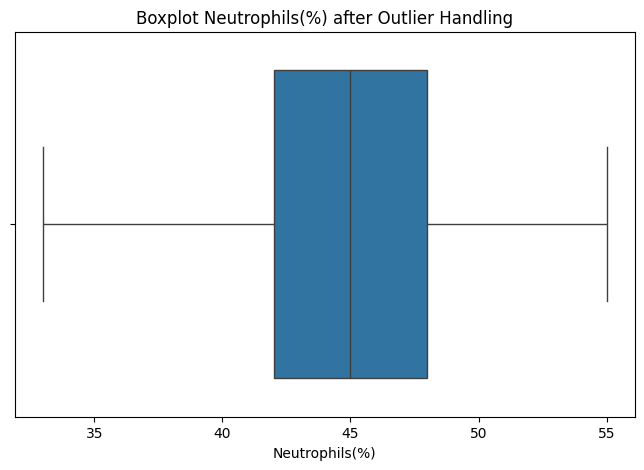

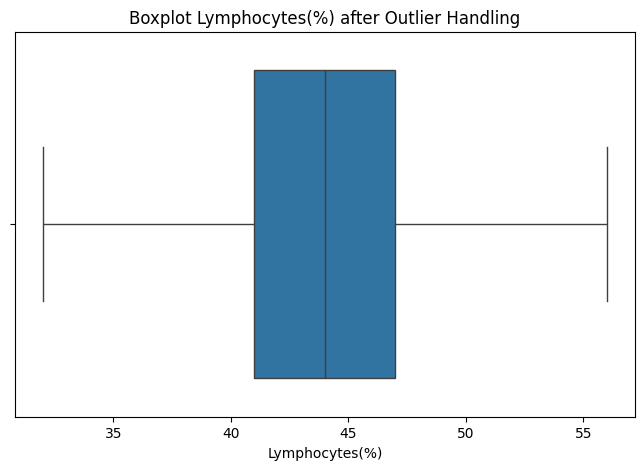

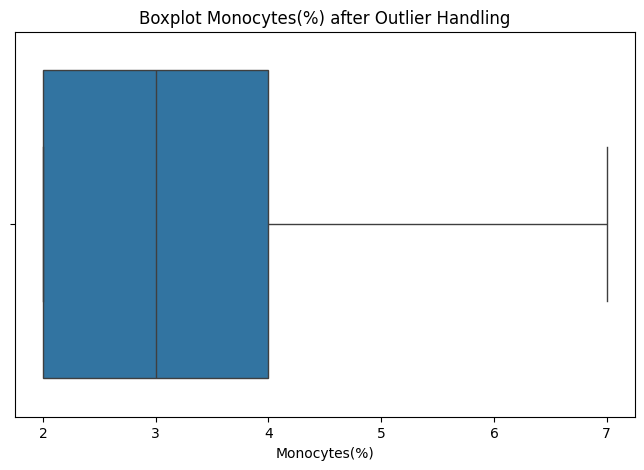

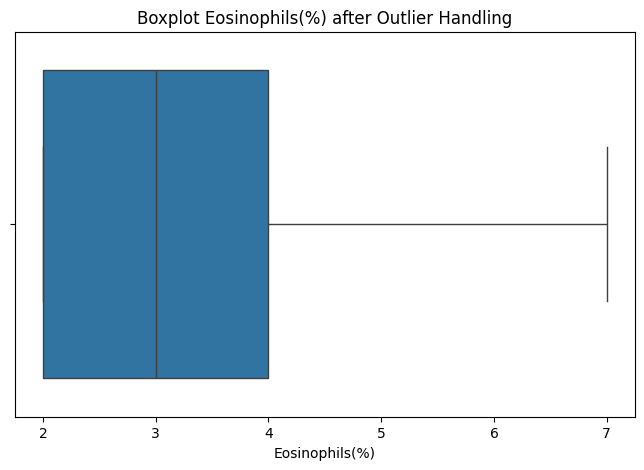

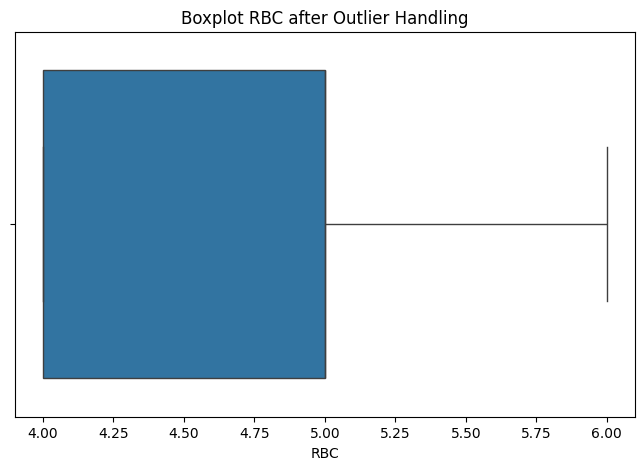

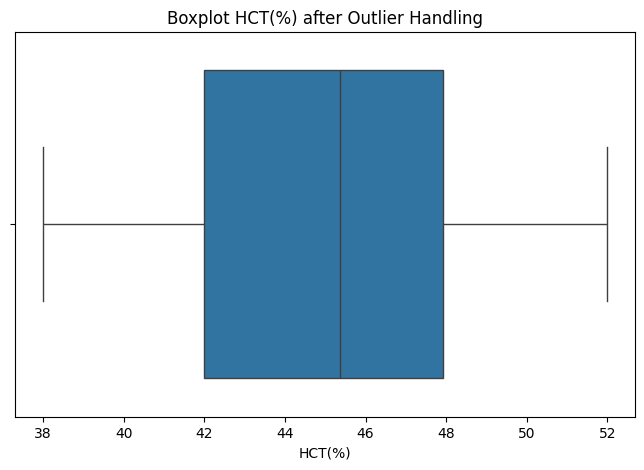

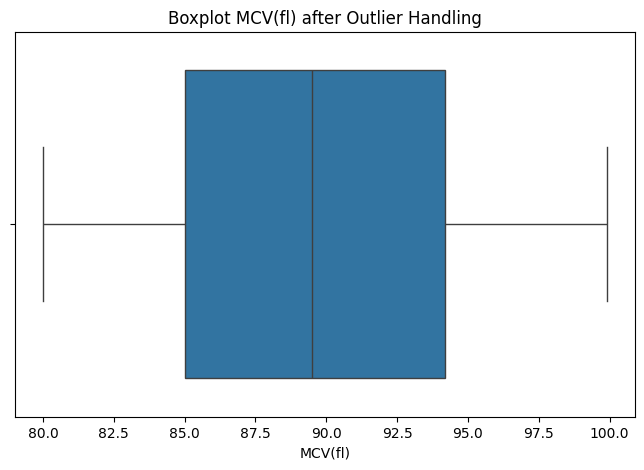

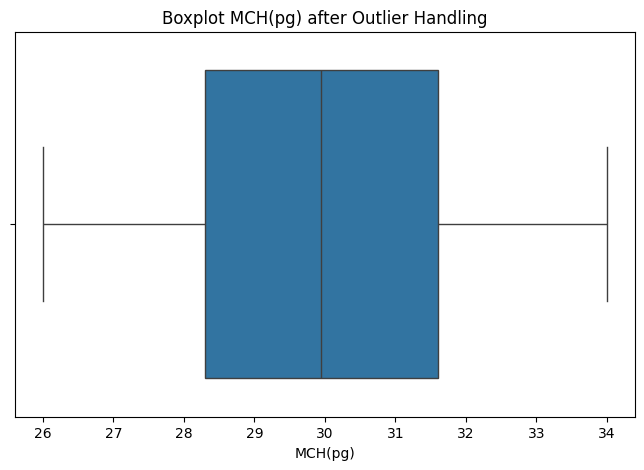

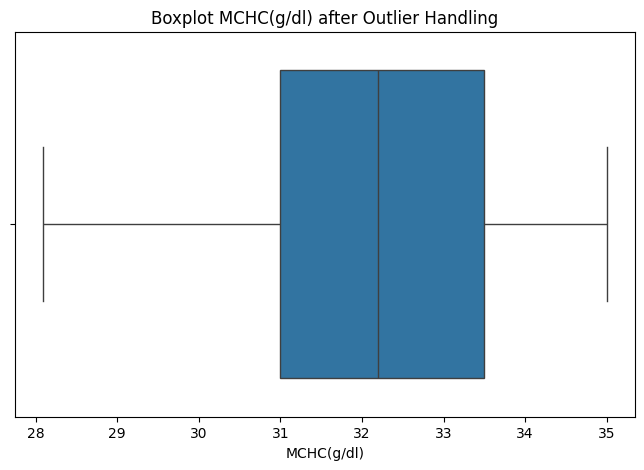

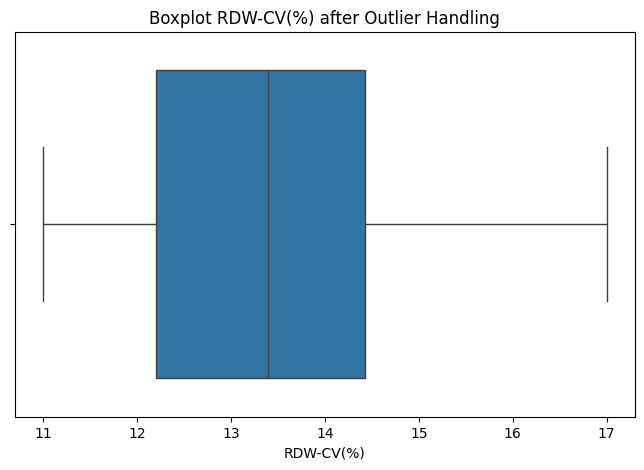

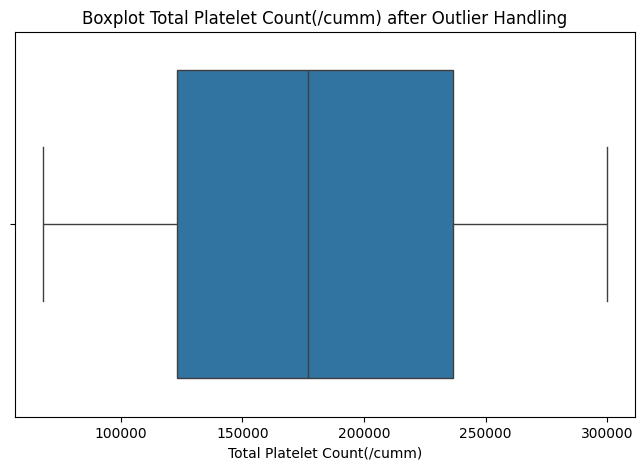

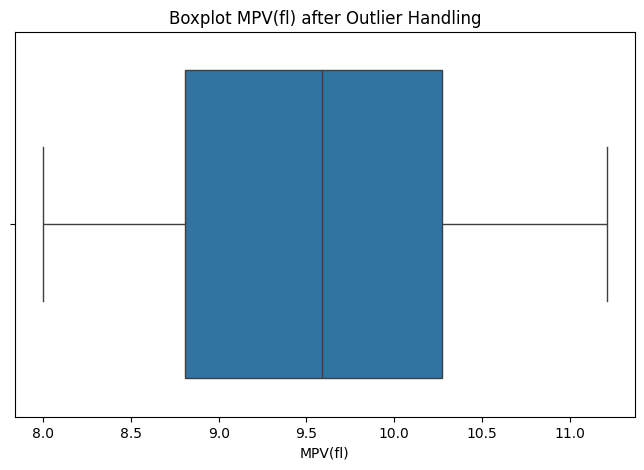

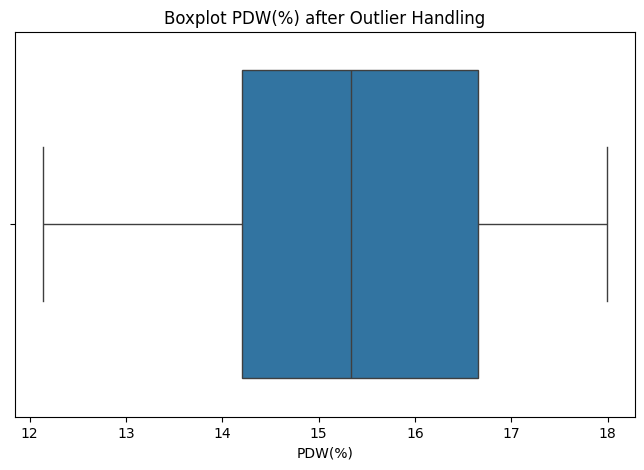

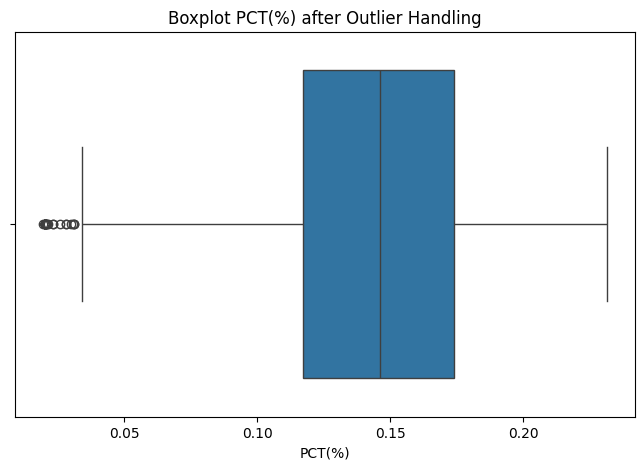

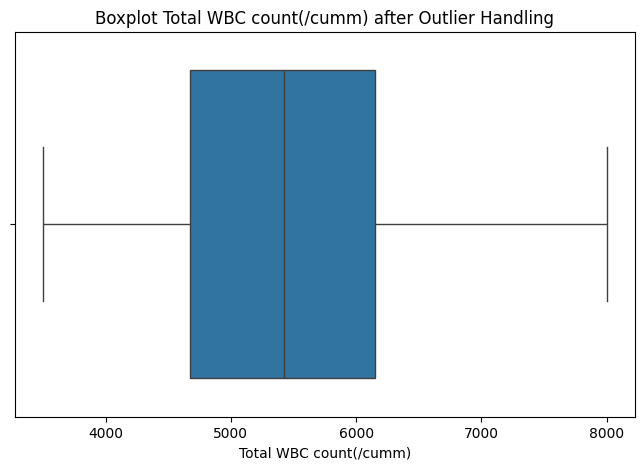

In [ ]:
# Boxplot after handle outlier
for i in numerical_cols:
    plt.figure(figsize=(8,5))
    sns.boxplot(x=df_clean[i])
    plt.title(f"Boxplot {i} after Outlier Handling")
    plt.xlabel(i)
    plt.show()

In [ ]:
# Encoding Target Variable
le = LabelEncoder()
y_encoded = le.fit_transform(df_clean['Result'])
class_names = le.classes_ # ['negative', 'positive']

### **Splitting Data**

In [ ]:
x = df_clean.drop(columns='Result')
y = y_encoded

In [ ]:
# Split the dataset to 70% train 30% test
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=42)

print(X_train.shape)
print(X_test.shape)

(807, 16)
(346, 16)


In [ ]:
X_train.head()

,Hemoglobin(g/dl),Neutrophils(%),Lymphocytes(%),Monocytes(%),Eosinophils(%),RBC,HCT(%),MCV(fl),MCH(pg),MCHC(g/dl),RDW-CV(%),Total Platelet Count(/cumm),MPV(fl),PDW(%),PCT(%),Total WBC count(/cumm)
1046,13.000,44.0,46.0,4.0,4.0,4.0,39.03,84.6,28.00,34.200,11.300,180782.0,10.18,16.790,0.1160,6952.0
1019,16.500,43.0,43.0,4.0,4.0,5.0,47.11,92.1,28.60,33.300,11.300,285457.0,10.00,13.780,0.1100,6759.0
31,16.440,45.0,49.0,3.0,4.0,6.0,50.38,98.0,30.12,32.480,14.830,174000.0,10.10,16.350,0.1360,7000.0
663,13.700,40.0,40.0,3.0,4.0,5.0,42.97,93.9,28.30,32.300,12.100,104119.0,10.88,14.490,0.1580,5470.0
311,14.569,48.0,34.0,2.0,3.0,5.0,47.43,85.0,30.42,31.683,14.921,140000.0,10.05,14.403,0.0521,4500.0


## **Feature Engineering**

### **Scaling**

In [ ]:
# Standard Scaler for big number range (1-100)
scaler = StandardScaler()
data = ['Monocytes(%)','Eosinophils(%)','RBC']
X_train[data] = scaler.fit_transform(X_train[data])
X_test[data] = scaler.transform(X_test[data])

In [ ]:
# Robut Scaler for small number range (1.000-100.000)
num_scaler=RobustScaler()
data_cols_to_scale = ['Hemoglobin(g/dl)','Neutrophils(%)','Lymphocytes(%)','HCT(%)','MCV(fl)','MCH(pg)','MCHC(g/dl)','RDW-CV(%)','Total Platelet Count(/cumm)','MPV(fl)','PDW(%)','PCT(%)','Total WBC count(/cumm)']
X_train[data_cols_to_scale] = num_scaler.fit_transform(X_train[data_cols_to_scale])
X_test[data_cols_to_scale] = num_scaler.transform(X_test[data_cols_to_scale])

### **Resampling (Smote)**

In [ ]:
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

In [ ]:
X_resampled

,Hemoglobin(g/dl),Neutrophils(%),Lymphocytes(%),Monocytes(%),Eosinophils(%),RBC,HCT(%),MCV(fl),MCH(pg),MCHC(g/dl),RDW-CV(%),Total Platelet Count(/cumm),MPV(fl),PDW(%),PCT(%),Total WBC count(/cumm)
0,-0.592593,-0.200000,0.333333,0.923605,1.037458,-1.057730,-1.089332,-0.521739,-0.565625,0.800000,-0.985915,0.045649,0.364865,0.611227,-0.535714,1.011214
1,0.703704,-0.400000,-0.166667,0.923605,1.037458,0.602947,0.312229,0.293478,-0.378125,0.440000,-0.985915,0.971145,0.243243,-0.640333,-0.642857,0.883905
2,0.681481,0.000000,0.833333,-0.080909,1.037458,2.263624,0.879445,0.934783,0.096875,0.112000,0.671362,-0.014315,0.310811,0.428274,-0.178571,1.042876
3,-0.333333,-1.000000,-0.666667,-0.080909,1.037458,0.602947,-0.405898,0.489130,-0.471875,0.040000,-0.610329,-0.632176,0.837838,-0.345114,0.214286,0.033641
4,-0.011481,0.600000,-1.666667,-1.085422,-0.061267,0.602947,0.367736,-0.478261,0.190625,-0.206800,0.714085,-0.314930,0.277027,-0.381289,-1.676786,-0.606201
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1151,0.065750,0.586738,-0.844385,0.856997,0.011587,0.602947,0.456891,-0.152174,-0.046596,-0.744996,0.453094,-0.526637,0.784147,-0.389377,-1.956080,-0.276385
1152,0.812861,-0.787945,-0.169178,-1.077854,-1.151714,-1.057730,-0.980960,-0.375767,-0.868236,0.880000,0.702810,-0.619398,0.804003,1.077048,-0.446563,-0.557047
1153,0.464790,-0.154933,0.575111,0.697255,2.136183,2.263624,0.707256,-0.247102,0.035167,-0.443510,0.814648,-0.247674,0.595351,0.624765,0.169524,0.081311
1154,0.089008,-1.888500,0.605774,0.923605,1.037458,-1.057730,0.007014,0.410718,-0.105027,0.064361,0.710745,-0.221682,-0.174899,-0.304652,-0.703992,0.470701


## **Model Testing and Hyperparameter Tuning**

### **Logistic Regression**

In [ ]:
log_reg_model = LogisticRegression(max_iter=2000, random_state=42)

In [ ]:
# HyperParameter Tuning
param_log = {
    'penalty': ['l1', 'l2', 'elasticnet'],
    'C': [0.01, 0.1, 1, 10],
    'solver': ['lbfgs', 'liblinear', 'saga'],
}

grid_log = GridSearchCV(log_reg_model, param_log, cv=5, scoring='accuracy', n_jobs=-1)

In [ ]:
grid_log.fit(X_resampled, y_resampled)

GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=2000, random_state=42),
             n_jobs=-1,
             param_grid={'C': [0.01, 0.1, 1, 10],
                         'penalty': ['l1', 'l2', 'elasticnet'],
                         'solver': ['lbfgs', 'liblinear', 'saga']},
             scoring='accuracy')

In [ ]:
print("\nBest Logistic Regression Params:", grid_log.best_params_)
y_pred_log = grid_log.predict(X_test)
print("\nLogistic Regression Accuracy:", accuracy_score(y_test, y_pred_log))
print(classification_report(y_test, y_pred_log))


Best Logistic Regression Params: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}

Logistic Regression Accuracy: 0.5895953757225434
              precision    recall  f1-score   support

           0       0.29      0.47      0.36        85
           1       0.78      0.63      0.70       261

    accuracy                           0.59       346
   macro avg       0.54      0.55      0.53       346
weighted avg       0.66      0.59      0.61       346



### **RandomForest**

In [ ]:
rf_model = RandomForestClassifier()

In [ ]:
param_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_rf = GridSearchCV(rf_model, param_rf, cv=5, scoring='accuracy', n_jobs=-1)

In [ ]:
grid_rf.fit(X_resampled, y_resampled)

GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=-1,
             param_grid={'max_depth': [5, 10, 20],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='accuracy')

In [ ]:
print("\nBest Random Forest Params:", grid_rf.best_params_)
y_pred_rf = grid_rf.predict(X_test)
print("\nRandom Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))


Best Random Forest Params: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}

Random Forest Accuracy: 0.7341040462427746
              precision    recall  f1-score   support

           0       0.43      0.26      0.32        85
           1       0.79      0.89      0.83       261

    accuracy                           0.73       346
   macro avg       0.61      0.57      0.58       346
weighted avg       0.70      0.73      0.71       346



### **Gradient Boost**

In [ ]:
gb_model = GradientBoostingClassifier()

In [ ]:
param_gb = {
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 300],
    'max_depth': [2, 3, 4]
}

grid_gb = GridSearchCV(gb_model, param_gb, cv=5, scoring='accuracy', n_jobs=-1)

In [ ]:
grid_gb.fit(X_resampled, y_resampled)

GridSearchCV(cv=5, estimator=GradientBoostingClassifier(), n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.05, 0.1],
                         'max_depth': [2, 3, 4],
                         'n_estimators': [100, 200, 300]},
             scoring='accuracy')

In [ ]:
print("\nBest Gradient Boosting Params:", grid_gb.best_params_)
y_pred_gb = grid_gb.predict(X_test)
print("\nGradient Boosting Accuracy:", accuracy_score(y_test, y_pred_gb))
print(classification_report(y_test, y_pred_gb))


Best Gradient Boosting Params: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300}

Gradient Boosting Accuracy: 0.7341040462427746
              precision    recall  f1-score   support

           0       0.44      0.32      0.37        85
           1       0.80      0.87      0.83       261

    accuracy                           0.73       346
   macro avg       0.62      0.59      0.60       346
weighted avg       0.71      0.73      0.72       346



### **Decision Tree (Classifier)**

In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)

In [ ]:
param_dt = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [None, 5, 10, 20, 30],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 6]
}

grid_dt = GridSearchCV(dt_model, param_dt, cv=5, scoring='accuracy', n_jobs=-1)

In [ ]:
grid_dt.fit(X_resampled, y_resampled)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy', 'log_loss'],
                         'max_depth': [None, 5, 10, 20, 30],
                         'min_samples_leaf': [1, 2, 4, 6],
                         'min_samples_split': [2, 5, 10, 20]},
             scoring='accuracy')

In [ ]:
print("\nBest Decision Tree Params:", grid_dt.best_params_)
y_pred_dt = grid_dt.predict(X_test)
print("\nDecision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))


Best Decision Tree Params: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}

Decision Tree Accuracy: 0.6647398843930635
              precision    recall  f1-score   support

           0       0.37      0.51      0.43        85
           1       0.82      0.72      0.76       261

    accuracy                           0.66       346
   macro avg       0.59      0.61      0.59       346
weighted avg       0.71      0.66      0.68       346



### **Model Performance Summary**

In [ ]:
models = {
    "Logistic Regression": (grid_log.best_estimator_, y_pred_log),
    "Random Forest": (grid_rf.best_estimator_, y_pred_rf),
    "Gradient Boosting": (grid_gb.best_estimator_, y_pred_gb),
    "Decision Tree": (grid_dt.best_estimator_, y_pred_dt)
}


In [ ]:
results = []

for name, (model, y_pred) in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.589595,0.784689,0.628352,0.697872,0.569574
Random Forest,0.734104,0.786441,0.888889,0.834532,0.584111
Gradient Boosting,0.734104,0.796491,0.869732,0.831502,0.573451
Decision Tree,0.664740,0.816594,0.716475,0.763265,0.612148


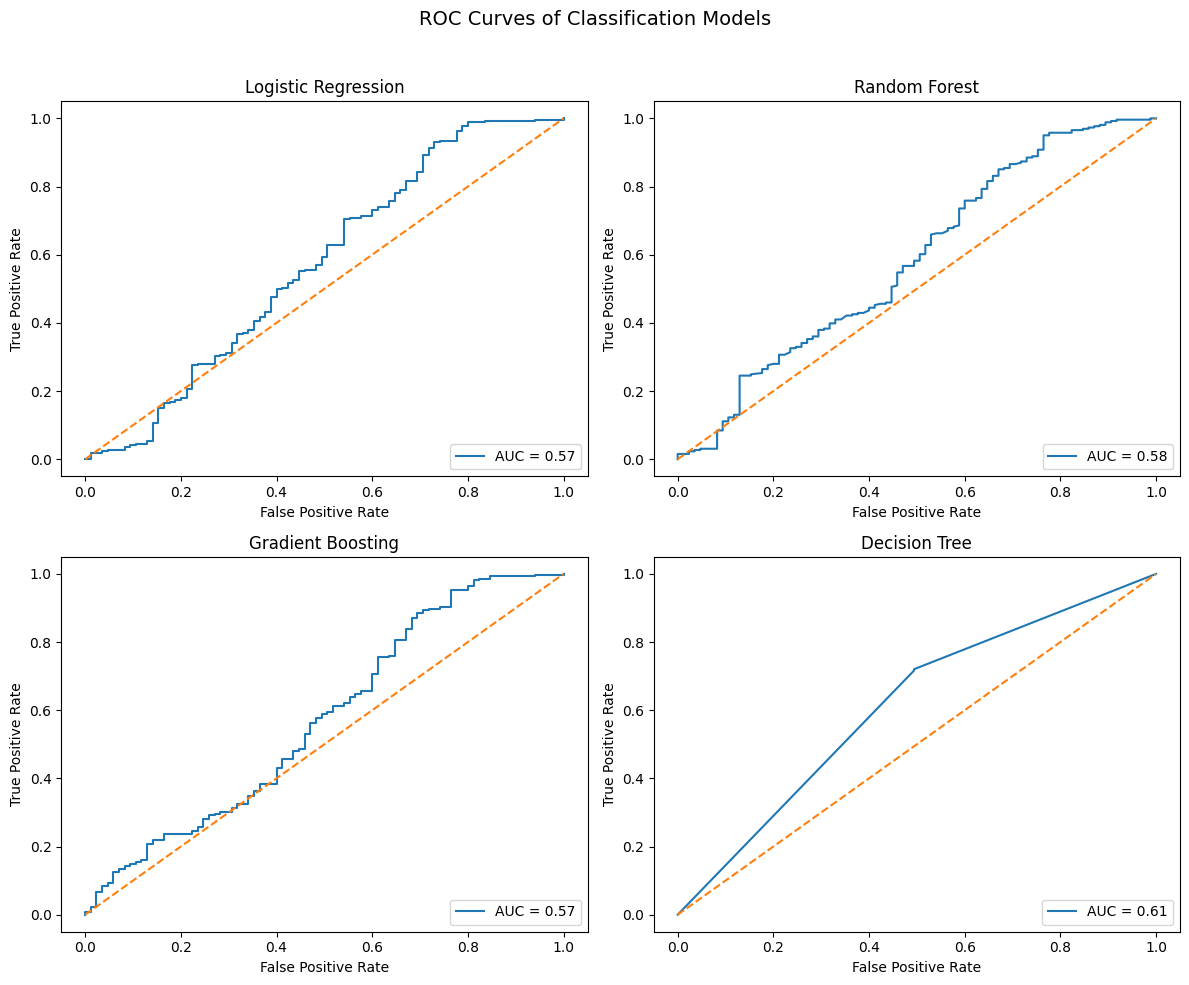

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, (name, (model, _)) in zip(axes, models.items()):
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    ax.plot(fpr, tpr, label=f"AUC = {auc_score:.2f}")
    ax.plot([0, 1], [0, 1], linestyle='--')
    ax.set_title(name)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")

plt.suptitle("ROC Curves of Classification Models", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

**NOTE**: After conducting training on various models, and the results show insignificant differences, this may be due to poor data quality.

## **Final Model & Evaluation**

In [ ]:
# Take the best parameter for previous XG Boost Tuning
best_gb = grid_gb.best_estimator_

In [ ]:
best_gb.fit(X_resampled, y_resampled)

GradientBoostingClassifier(max_depth=4, n_estimators=300)

In [ ]:
fin_y_pred_rf = best_gb.predict(X_test)

In [ ]:
accuracy_gb = accuracy_score(y_test, fin_y_pred_rf)
conf_matrix_gb = confusion_matrix(y_test, fin_y_pred_rf)
class_report_gb = classification_report(y_test, fin_y_pred_rf)

print(f"\nAccuracy: {accuracy_gb:.2f}")
print("\nConfusion Matrix:\n", conf_matrix_gb)
print("\nClassification Report:\n", class_report_gb)


Accuracy: 0.73

Confusion Matrix:
 [[ 27  58]
 [ 35 226]]

Classification Report:
               precision    recall  f1-score   support

           0       0.44      0.32      0.37        85
           1       0.80      0.87      0.83       261

    accuracy                           0.73       346
   macro avg       0.62      0.59      0.60       346
weighted avg       0.71      0.73      0.72       346



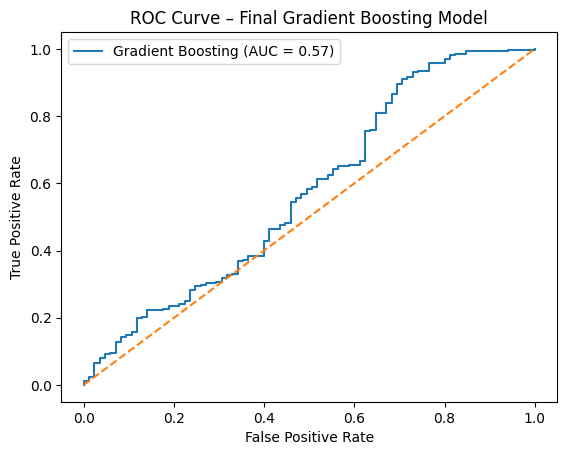

In [ ]:
y_prob_gb = best_gb.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_prob_gb)
auc_gb = roc_auc_score(y_test, y_prob_gb)

plt.figure()
plt.plot(fpr, tpr, label=f"Gradient Boosting (AUC = {auc_gb:.2f})")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Final Gradient Boosting Model")
plt.legend()
plt.show()

In [ ]:
# Take best parameter
fin_model_rf = grid_rf

In [ ]:
fin_model_rf.fit(X_resampled, y_resampled)

GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=-1,
             param_grid={'max_depth': [5, 10, 20],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='accuracy')

In [ ]:
Y_pred_rf = fin_model_rf.predict(X_test)

In [ ]:
accuracy_gb = accuracy_score(y_test, fin_y_pred_rf)
conf_matrix_gb = confusion_matrix(y_test, fin_y_pred_rf)
class_report_gb = classification_report(y_test, fin_y_pred_rf)

print(f"\nAccuracy: {accuracy_gb:.2f}")
print("\nConfusion Matrix:\n", conf_matrix_gb)
print("\nClassification Report:\n", class_report_gb)


Accuracy: 0.73

Confusion Matrix:
 [[ 27  58]
 [ 35 226]]

Classification Report:
               precision    recall  f1-score   support

           0       0.44      0.32      0.37        85
           1       0.80      0.87      0.83       261

    accuracy                           0.73       346
   macro avg       0.62      0.59      0.60       346
weighted avg       0.71      0.73      0.72       346



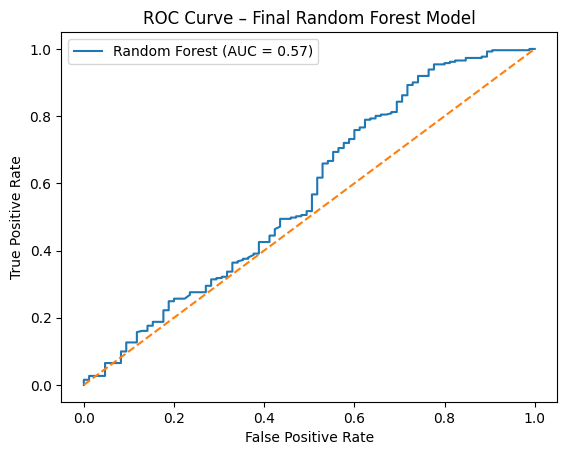

In [ ]:
y_prob_rf = fin_model_rf.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_prob_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)

plt.figure()
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc_rf:.2f})")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Final Random Forest Model")
plt.legend()
plt.show()

**Conclusion**, Random Forest is the model with the best performance in the context of classifying Dengue Fever Disease, because in the context of classifying dengue fever disease, the Recall value is prioritized, so even though the AUC value is lower than the Decision Tree, we still choose random forest as our final base model.